# 01 · CNN propia desde cero y medición del entrenamiento en GPU

Primer notebook de la réplica de SE-ResNet-MTL. Antes de gastar horas de GPU con ResNet50, montamos y medimos **toda la tubería** con una CNN pequeña diseñada a mano:

datos (`splits/split_v1.csv`) → aumentación → modelo → entrenamiento con los hiperparámetros del artículo → métricas → registro.

**Hoja de ruta de la réplica**

| Notebook | Modelo | Artículo |
|---|---|---|
| **01 (este)** | CNN propia desde cero | — (referencia mínima y prueba de la tubería) |
| 02 | ResNet50 desde cero | Baseline: 78.11 % acc |
| 03 | ResNet50 + transfer learning (backbone congelado) | 93.53 % |
| 04 | SE-ResNet50 + TL (comparativa de activaciones) | 95.52 % |
| 05 | SE-ResNet-MTL (MAML, 5-way 1/5-shot) | 0.905 / 0.915 |

**Qué se mide:** tiempo por época (separando la espera de datos del cómputo), imágenes/s, memoria pico de la GPU, utilización/potencia/temperatura (NVML), latencia de inferencia, parámetros, FLOPs y el coste de subir el batch size o activar precisión mixta.

> **Test no se toca.** Este notebook solo carga train y val. El test se evalúa una única vez al final del proyecto.

Ejecuta este notebook en **WSL** con el kernel `mars`.

## 0. Configuración, reproducibilidad y entorno

`PYTORCH_CUDA_ALLOC_CONF` debe fijarse **antes** de importar torch para que tenga efecto.

In [2]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import copy, json, platform, random, threading, time
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2 as T
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

ROOT = Path.cwd()
DATA = ROOT / "data"
SPLIT_CSV = ROOT / "splits" / "split_v1.csv"
RUN_NAME = "cnn_baseline_v1"
RESULTS_DIR = ROOT / "results" / RUN_NAME

assert DATA.exists(), f"No encuentro {DATA}: abre el notebook desde la raíz del repo"
assert SPLIT_CSV.exists(), "Falta splits/split_v1.csv: ejecuta antes la sección 9 de experiments.ipynb"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
@dataclass
class Config:
    seed: int = 42
    img_size: int = 224

    batch_size: int = 8
    lr: float = 1e-3
    weight_decay: float = 1e-4
    max_epochs: int = 200
    es_patience: int = 20          # early stopping sobre val loss
    plateau_factor: float = 0.5    # ReduceLROnPlateau sobre val acc
    plateau_patience: int = 5
    # Aumentación (valores no especificados en el artículo -> decisión propia, ver experiments.ipynb §10)
    brightness: float = 0.3
    contrast: float = 0.3
    crop_scale: tuple = (0.7, 1.0)
    noise_std: float = 0.03
    # Modelo
    widths: tuple = (32, 64, 128, 256, 256)
    dropout: float = 0.3
    # Sistema
    num_workers: int = 0           # los datos van cacheados en RAM: no hacen falta workers
    use_amp: bool = False          # el artículo no usa precisión mixta

cfg = Config()

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(cfg.seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

assert torch.cuda.is_available(), "No hay GPU: ¿estás usando el kernel mars dentro de WSL?"
device = torch.device("cuda")
props = torch.cuda.get_device_properties(device)

env_info = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version(),
    "gpu": props.name,
    "vram_GB": round(props.total_memory / 1024**3, 2),
    "compute_capability": f"{props.major}.{props.minor}",
    "kernel": platform.uname().release,
    "cpu_threads": os.cpu_count(),
}
pd.Series(env_info, name="entorno").to_frame()

,entorno
python,3.12.3
torch,2.15.0+cu132
torchvision,0.29.2+cu132
cuda,13.2
cudnn,92600
gpu,NVIDIA GeForce RTX 3060
vram_GB,12.0
compute_capability,8.6
kernel,6.18.40.1-microsoft-standard-WSL2
cpu_threads,20


## 1. Datos

### 1.1 Partición
Se lee la partición propia (agrupada por sol, 70/20/10) y se comprueba otra vez que no haya soles compartidos.

In [4]:
split_df = pd.read_csv(SPLIT_CSV)
split_df["abs_path"] = split_df["path"].map(lambda p: str(ROOT / p))

CLASSES = sorted(split_df["label"].unique())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
split_df["y"] = split_df["label"].map(CLASS_TO_IDX)

assert split_df.groupby("sol")["split"].nunique().max() == 1, "Hay soles en más de un split"
print("Clases:", CLASS_TO_IDX)
pd.crosstab(split_df["label"], split_df["split"], margins=True)[["train", "val", "test", "All"]]

Clases: {'artifacts': 0, 'invalid': 1, 'regolith': 2, 'rocks': 3, 'rover_tracks': 4}


split,train,val,test,All
label,,,,
artifacts,135,38,20,193
invalid,122,36,18,176
regolith,159,46,22,227
rocks,156,45,22,223
rover_tracks,127,36,18,181
All,699,201,100,1000


### 1.2 Dataset cacheado en RAM

Leer los JPEG desde `/mnt/c` en WSL es lento (el disco de Windows se monta por red, protocolo 9P), y decodificar una imagen de 560×500 en cada época gasta CPU. Como solo hay 1000 imágenes, se **decodifican y redimensionan una vez** a 224×224 y se guardan como `uint8`: 3·224·224 bytes ≈ 150 KB por imagen, unos **100 MB para train** y 30 MB para val.

El redimensionado es `Resize((224, 224))` (deforma un 12 % en horizontal), la opción elegida en la sección 6 del EDA. Las aumentaciones se aplican después, sobre el tensor cacheado, así que son distintas en cada época.

In [5]:
def load_resized(path, size):
    # PIL hace antialias al reducir: equivale a Resize((size, size))
    with Image.open(path) as img:
        img = img.convert("RGB").resize((size, size), Image.BILINEAR)
    return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1).contiguous()   # uint8 (3, H, W)


class CachedImageDataset(Dataset):
    # Imágenes decodificadas una vez y guardadas en RAM como uint8; la transformación se aplica al vuelo.
    def __init__(self, frame, size, transform=None):
        t0 = time.perf_counter()
        self.images = torch.stack([load_resized(p, size) for p in frame["abs_path"]])
        self.labels = torch.tensor(frame["y"].to_numpy(), dtype=torch.long)
        self.transform = transform
        self.load_seconds = time.perf_counter() - t0

    def with_transform(self, transform):
        # Copia ligera que comparte las imágenes cacheadas pero con otra transformación
        new = copy.copy(self)
        new.transform = transform
        return new

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        x = self.images[i]
        if self.transform is not None:
            x = self.transform(x)
        return x, self.labels[i]

### 1.3 Transformaciones

- **Train:** recorte aleatorio, volteo horizontal, brillo/contraste y ruido gaussiano, como en la Fig. 2 del artículo. Después, normalización con las estadísticas de ImageNet.
- **Val/test:** solo conversión a float y normalización.

Para una CNN desde cero también valdrían las estadísticas de Marte de la sección 6. Se usan las de ImageNet para que todos los modelos de la réplica reciban la misma entrada.

In [42]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class AddGaussianNoise(nn.Module):
    # Ruido gaussiano sobre un tensor float en [0, 1], recortado para seguir en [0, 1]
    def __init__(self, std=0.03, p=0.5):
        super().__init__()
        self.std, self.p = std, p

    def forward(self, x):
        if torch.rand(1).item() < self.p:
            x = (x + torch.randn_like(x) * self.std).clamp(0, 1)
        return x


train_tf = T.Compose([
    T.ToImage(),
    T.RandomResizedCrop(cfg.img_size, scale=cfg.crop_scale, ratio=(0.9, 1.1), antialias=True),
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(brightness=cfg.brightness, contrast=cfg.contrast),
    T.ToDtype(torch.float32, scale=True),
    AddGaussianNoise(cfg.noise_std, p=0.5),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tf = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

In [7]:
train_ds = CachedImageDataset(split_df[split_df["split"] == "train"], cfg.img_size, train_tf)
val_ds = CachedImageDataset(split_df[split_df["split"] == "val"], cfg.img_size, eval_tf)
train_eval_ds = train_ds.with_transform(eval_tf)    # train sin aumentación, para medir Acc Gap
# El test NO se carga en este notebook.

for name, ds in [("train", train_ds), ("val", val_ds)]:
    print(f"{name:5s}: {len(ds):4d} imágenes | caché {ds.images.numel() / 1024**2:6.1f} MB | "
          f"carga {ds.load_seconds:5.1f} s ({len(ds) / ds.load_seconds:.0f} img/s)")

loader_gen = torch.Generator().manual_seed(cfg.seed)
train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True,
                          num_workers=cfg.num_workers, pin_memory=True, generator=loader_gen)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=cfg.num_workers, pin_memory=True)
train_eval_loader = DataLoader(train_eval_ds, batch_size=64, shuffle=False, num_workers=cfg.num_workers, pin_memory=True)
print(f"Batches por época: train {len(train_loader)}, val {len(val_loader)}")

train:  699 imágenes | caché  100.3 MB | carga   6.4 s (109 img/s)
val  :  201 imágenes | caché   28.9 MB | carga   1.7 s (115 img/s)
Batches por época: train 88, val 4


### 1.4 Comprobación visual de un batch aumentado
Antes de entrenar, comprueba que imágenes y etiquetas son coherentes después de la tubería completa. Hay que desnormalizar para poder verlas.

batch: (16, 3, 224, 224) torch.float32 media -0.00, std 0.94


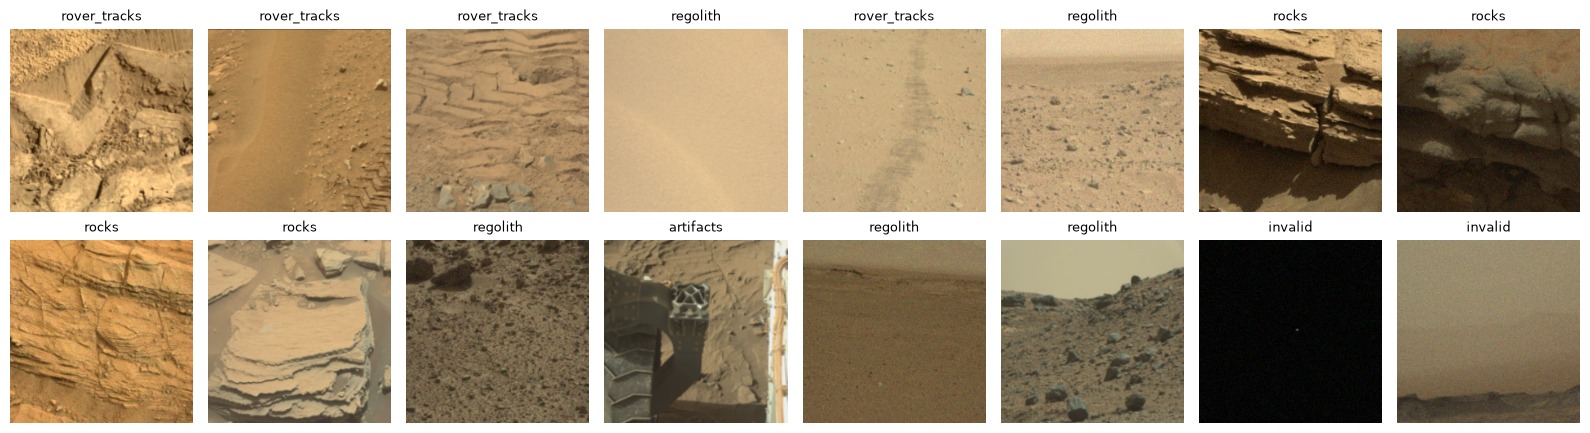

In [43]:
def denormalize(x):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x * std + mean).clamp(0, 1)

xb, yb = next(iter(DataLoader(train_ds, batch_size=16, shuffle=True,
                              generator=torch.Generator().manual_seed(0))))
print("batch:", tuple(xb.shape), xb.dtype, f"media {xb.mean():.2f}, std {xb.std():.2f}")

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, x, y in zip(axes.flat, xb, yb):
    ax.imshow(denormalize(x).permute(1, 2, 0).numpy())
    ax.set_title(CLASSES[y], fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 2. Modelo: `MarsCNN`

Propuesta de CNN a mano, al estilo VGG pero moderna:

- **5 bloques** `[Conv3×3 → BN → ReLU] ×2 → MaxPool2×2`. La resolución baja 224 → 112 → 56 → 28 → 14 → 7 y los canales suben 32 → 64 → 128 → 256 → 256.
- **BatchNorm:** permite entrenar desde cero con LR 1e-3 sin que la red diverja. Las convoluciones no llevan bias porque BN ya lo aporta.
- **Global Average Pooling** en lugar de capas densas grandes. Reduce mucho los parámetros (menos sobreajuste con solo 700 imágenes) y es lo mismo que hace ResNet antes de su capa `fc`.
- **Dropout 0.3 + Linear(256 → 5).**
- Inicialización **Kaiming** (He), la adecuada para ReLU.

Tiene unos 2.3 M parámetros, 10 veces menos que ResNet50 (23.5 M).

In [10]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )


class MarsCNN(nn.Module):
    def __init__(self, n_classes=5, widths=(32, 64, 128, 256, 256), dropout=0.3):
        super().__init__()
        blocks, c_in = [], 3
        for w in widths:
            blocks.append(conv_block(c_in, w))
            c_in = w
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, n_classes))
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, std=0.01)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.head(self.pool(self.features(x)))


def make_model():
    return MarsCNN(len(CLASSES), cfg.widths, cfg.dropout)

### 2.1 Resumen: forma de salida y parámetros por bloque, FLOPs y comparación con ResNet50
`FlopCounterMode` cuenta FLOPs: una multiplicación-suma cuenta como 2. Algunos artículos dan MACs, que son la mitad.

In [11]:
from torch.utils.flop_counter import FlopCounterMode

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def count_gflops(model, size=224):
    model.eval()
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        model(torch.zeros(1, 3, size, size))
    return fc.get_total_flops() / 1e9

tmp = make_model().eval()
x, rows = torch.zeros(1, 3, cfg.img_size, cfg.img_size), []
with torch.no_grad():
    stages = [(f"block{i + 1}", b) for i, b in enumerate(tmp.features)] + [("gap", tmp.pool), ("head", tmp.head)]
    for name, module in stages:
        x = module(x)
        rows.append({"capa": name, "salida": tuple(x.shape[1:]), "parámetros": count_params(module)})
display(pd.DataFrame(rows).set_index("capa"))

resnet_ref = torchvision.models.resnet50(num_classes=len(CLASSES))
model_stats = pd.DataFrame({
    "parámetros (M)": [count_params(tmp) / 1e6, count_params(resnet_ref) / 1e6],
    "GFLOPs / imagen": [count_gflops(tmp), count_gflops(resnet_ref)],
}, index=["MarsCNN", "ResNet50"]).round(2)
del tmp, resnet_ref
model_stats

,salida,parámetros
capa,,
block1,"(32, 112, 112)",10208
block2,"(64, 56, 56)",55552
block3,"(128, 28, 28)",221696
block4,"(256, 14, 14)",885760
block5,"(256, 7, 7)",1180672
gap,"(256, 1, 1)",0
head,"(5,)",1285


,parámetros (M),GFLOPs / imagen
MarsCNN,2.36,5.64
ResNet50,23.52,8.17


## 3. Herramientas de medición

- **`GPUMonitor`:** un hilo en segundo plano lee de NVML cada 0.5 s la utilización, la memoria, la potencia y la temperatura de la GPU. Necesita `pip install nvidia-ml-py`; si no está instalado, el notebook sigue funcionando sin estas métricas. En WSL algunas lecturas, como la potencia, pueden salir vacías.
- **Tiempo por batch dividido en dos:**
  - *espera de datos*: lo que tarda el `DataLoader` en entregar el batch;
  - *cómputo*: copia a la GPU, forward, backward y optimizador.

  Las llamadas a la GPU son asíncronas, así que medir con `time.perf_counter()` solo es fiable si hay una sincronización. Aquí la hace `loss.item()`, que espera a que la GPU termine.
- **Memoria pico:** `torch.cuda.max_memory_allocated()` es la memoria que reservan los tensores de PyTorch. NVML muestra más, porque incluye el contexto CUDA y la caché del allocator.

In [12]:
class GPUMonitor:
    # Muestrea métricas NVML en un hilo aparte
    def __init__(self, interval=0.5, index=0):
        self.interval, self.samples, self.available = interval, [], False
        self._stop = threading.Event()
        try:
            import pynvml
            pynvml.nvmlInit()
            self._nvml, self._handle = pynvml, pynvml.nvmlDeviceGetHandleByIndex(index)
            self.available = True
        except Exception as e:
            print(f"GPUMonitor desactivado ({type(e).__name__}: {e}). Instala con: pip install nvidia-ml-py")

    def _read(self):
        n, h = self._nvml, self._handle
        sample = {"t": time.perf_counter()}
        readers = {
            "util_pct": lambda: n.nvmlDeviceGetUtilizationRates(h).gpu,
            "mem_used_MB": lambda: n.nvmlDeviceGetMemoryInfo(h).used / 1024**2,
            "power_W": lambda: n.nvmlDeviceGetPowerUsage(h) / 1000,
            "temp_C": lambda: n.nvmlDeviceGetTemperature(h, n.NVML_TEMPERATURE_GPU),
        }
        for key, read in readers.items():
            try:
                sample[key] = float(read())
            except Exception:
                sample[key] = np.nan
        return sample

    def _loop(self):
        while not self._stop.is_set():
            self.samples.append(self._read())
            self._stop.wait(self.interval)

    def start(self):
        if self.available:
            self.t0 = time.perf_counter()
            self._thread = threading.Thread(target=self._loop, daemon=True)
            self._thread.start()
        return self

    def stop(self):
        if self.available:
            self._stop.set()
            self._thread.join()
        return self.to_frame()

    def to_frame(self):
        frame = pd.DataFrame(list(self.samples))
        if not frame.empty:
            frame["t"] -= self.t0
        return frame

    def summary_since(self, t_start):
        s = [x for x in list(self.samples) if x["t"] >= t_start]
        if not s:
            return {}
        f = pd.DataFrame(s)
        return {"gpu_util_mean": f["util_pct"].mean(), "gpu_mem_used_MB_max": f["mem_used_MB"].max(),
                "gpu_power_W_mean": f["power_W"].mean(), "gpu_temp_C_max": f["temp_C"].max()}

## 4. Bucle de entrenamiento

Hiperparámetros del artículo: Adam (LR 1e-3, weight decay 1e-4), entropía cruzada, batch 8, `ReduceLROnPlateau` (×0.5, paciencia 5) sobre la val acc, early stopping con paciencia 20 y máximo 200 épocas. Se guarda el checkpoint con **menor pérdida de validación**.

`GradScaler` y `autocast` quedan desactivados mientras `use_amp=False`. Están para medir más adelante el efecto de la precisión mixta.

In [13]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    # Una pasada por loader. Si hay optimizer entrena; si no, solo evalúa. Devuelve métricas y tiempos.
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    data_s = compute_s = 0.0
    torch.cuda.reset_peak_memory_stats()
    t_start = t_prev = time.perf_counter()

    with torch.set_grad_enabled(training):
        for x, y in loader:
            t_batch = time.perf_counter()
            data_s += t_batch - t_prev                       # espera del DataLoader

            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=cfg.use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            bs = y.size(0)
            total_loss += loss.item() * bs                   # .item() sincroniza CPU y GPU
            correct += (logits.argmax(1) == y).sum().item()
            n += bs
            t_prev = time.perf_counter()
            compute_s += t_prev - t_batch

    elapsed = time.perf_counter() - t_start
    return {"loss": total_loss / n, "acc": correct / n, "time_s": elapsed, "data_s": data_s,
            "compute_s": compute_s, "img_per_s": n / elapsed,
            "peak_mem_MB": torch.cuda.max_memory_allocated() / 1024**2}


def fit(model, train_loader, val_loader, cfg, ckpt_path, monitor=None):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=cfg.plateau_factor, patience=cfg.plateau_patience)
    scaler = torch.amp.GradScaler("cuda", enabled=cfg.use_amp)

    history, best_val_loss, best_epoch, epochs_no_improve = [], float("inf"), 0, 0
    t_fit = time.perf_counter()
    print(" ep | train loss/acc | val loss/acc  |   lr    | época  img/s | mem pico")
    for epoch in range(1, cfg.max_epochs + 1):
        t0 = time.perf_counter()
        tr = run_epoch(model, train_loader, criterion, optimizer, scaler)
        va = run_epoch(model, val_loader, criterion)
        lr = optimizer.param_groups[0]["lr"]
        scheduler.step(va["acc"])

        row = {"epoch": epoch, "lr": lr,
               **{f"train_{k}": v for k, v in tr.items()},
               **{f"val_{k}": v for k, v in va.items()},
               "epoch_s": time.perf_counter() - t0}
        if monitor is not None:
            row.update(monitor.summary_since(t0))

        improved = va["loss"] < best_val_loss
        if improved:
            best_val_loss, best_epoch, epochs_no_improve = va["loss"], epoch, 0
            torch.save({"model": model.state_dict(), "epoch": epoch, "val_loss": va["loss"],
                        "val_acc": va["acc"], "classes": CLASSES, "cfg": asdict(cfg)}, ckpt_path)
        else:
            epochs_no_improve += 1
        history.append(row)

        print(f"{epoch:3d} | {tr['loss']:.3f} / {tr['acc']:.3f} | {va['loss']:.3f} / {va['acc']:.3f} | "
              f"{lr:.1e} | {row['epoch_s']:5.1f}s {tr['img_per_s']:5.0f} | {tr['peak_mem_MB']:5.0f} MB"
              + ("  *" if improved else ""))
        if epochs_no_improve >= cfg.es_patience:
            print(f"Early stopping: {cfg.es_patience} épocas sin mejorar la val loss")
            break

    summary = {"best_epoch": best_epoch, "best_val_loss": best_val_loss, "epochs_run": epoch,
               "train_time_s": time.perf_counter() - t_fit}
    return pd.DataFrame(history), summary

## 5. Entrenamiento

Coste estimado: unas 700 imágenes por época con batch 8 son 88 pasos, unos pocos segundos por época en la RTX 3060. Con early stopping debería acabar en pocos minutos.

In [24]:
set_seed(cfg.seed)
model = make_model().to(device)
ckpt_path = RESULTS_DIR / "best.pt"

monitor = GPUMonitor(interval=0.5).start()
try:
    history, fit_summary = fit(model, train_loader, val_loader, cfg, ckpt_path, monitor)
finally:
    gpu_trace = monitor.stop()

history.to_csv(RESULTS_DIR / "history.csv", index=False)
if not gpu_trace.empty:
    gpu_trace.to_csv(RESULTS_DIR / "gpu_trace.csv", index=False)
fit_summary

 ep | train loss/acc | val loss/acc  |   lr    | época  img/s | mem pico
  1 | 1.436 / 0.386 | 1.627 / 0.428 | 1.0e-03 |   6.8s   112 |   693 MB  *
  2 | 1.262 / 0.471 | 1.114 / 0.488 | 1.0e-03 |   4.6s   161 |   693 MB  *
  3 | 1.197 / 0.484 | 1.338 / 0.512 | 1.0e-03 |   4.3s   173 |   693 MB
  4 | 1.145 / 0.535 | 0.882 / 0.637 | 1.0e-03 |   4.2s   178 |   693 MB  *
  5 | 1.049 / 0.568 | 0.854 / 0.647 | 1.0e-03 |   4.7s   160 |   693 MB  *
  6 | 1.059 / 0.564 | 0.933 / 0.612 | 1.0e-03 |   4.3s   174 |   693 MB
  7 | 1.016 / 0.597 | 1.314 / 0.582 | 1.0e-03 |   4.3s   174 |   693 MB
  8 | 0.952 / 0.617 | 0.754 / 0.701 | 1.0e-03 |   4.7s   160 |   693 MB  *
  9 | 0.960 / 0.617 | 0.782 / 0.697 | 1.0e-03 |   4.8s   157 |   693 MB
 10 | 0.880 / 0.635 | 0.953 / 0.701 | 1.0e-03 |   4.4s   170 |   693 MB
 11 | 0.873 / 0.638 | 0.866 / 0.632 | 1.0e-03 |   4.3s   175 |   693 MB
 12 | 0.806 / 0.677 | 0.766 / 0.682 | 1.0e-03 |   4.3s   173 |   693 MB
 13 | 0.813 / 0.680 | 0.745 / 0.721 | 1.0e-03 | 

{'best_epoch': 72,
 'best_val_loss': 0.2736374560873307,
 'epochs_run': 92,
 'train_time_s': 407.90586808899934}

## 6. Curvas de aprendizaje y del proceso

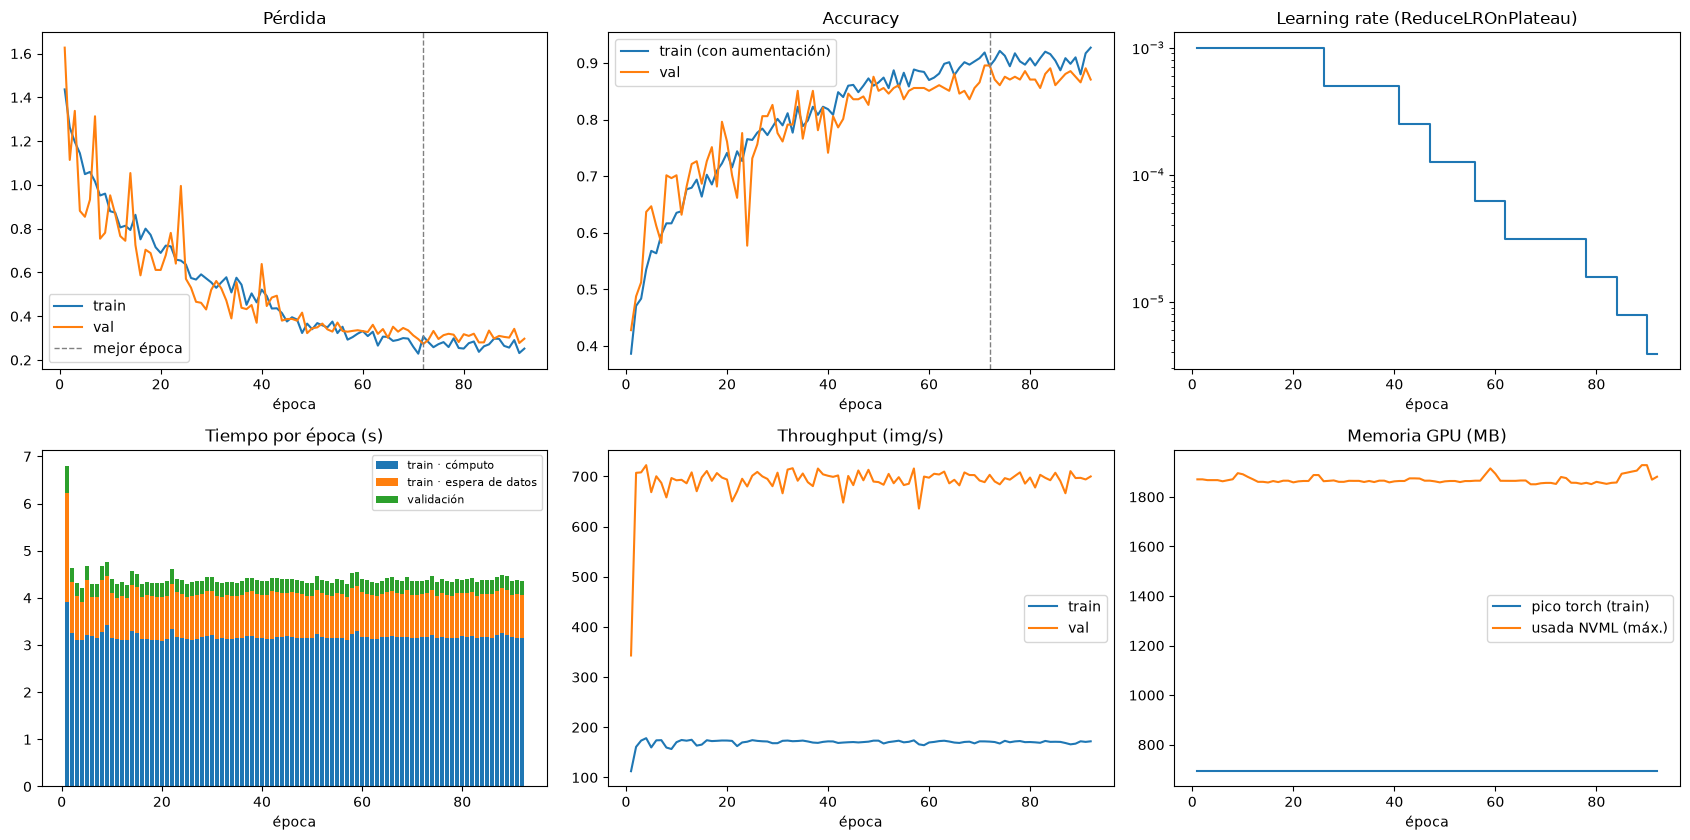

Tiempo total 408 s en 92 épocas (4.4 s/época)
Reparto: cómputo train 72%, espera de datos 21%, validación 7%


In [25]:
h = history
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))

ax = axes[0, 0]
ax.plot(h.epoch, h.train_loss, label="train")
ax.plot(h.epoch, h.val_loss, label="val")
ax.axvline(fit_summary["best_epoch"], ls="--", c="gray", lw=1, label="mejor época")
ax.set_title("Pérdida"); ax.set_xlabel("época"); ax.legend()

ax = axes[0, 1]
ax.plot(h.epoch, h.train_acc, label="train (con aumentación)")
ax.plot(h.epoch, h.val_acc, label="val")
ax.axvline(fit_summary["best_epoch"], ls="--", c="gray", lw=1)
ax.set_title("Accuracy"); ax.set_xlabel("época"); ax.legend()

ax = axes[0, 2]
ax.step(h.epoch, h.lr, where="post")
ax.set_yscale("log"); ax.set_title("Learning rate (ReduceLROnPlateau)"); ax.set_xlabel("época")

ax = axes[1, 0]
ax.bar(h.epoch, h.train_compute_s, label="train · cómputo")
ax.bar(h.epoch, h.train_data_s, bottom=h.train_compute_s, label="train · espera de datos")
ax.bar(h.epoch, h.val_time_s, bottom=h.train_compute_s + h.train_data_s, label="validación")
ax.set_title("Tiempo por época (s)"); ax.set_xlabel("época"); ax.legend(fontsize=8)

ax = axes[1, 1]
ax.plot(h.epoch, h.train_img_per_s, label="train")
ax.plot(h.epoch, h.val_img_per_s, label="val")
ax.set_title("Throughput (img/s)"); ax.set_xlabel("época"); ax.legend()

ax = axes[1, 2]
ax.plot(h.epoch, h.train_peak_mem_MB, label="pico torch (train)")
if "gpu_mem_used_MB_max" in h:
    ax.plot(h.epoch, h.gpu_mem_used_MB_max, label="usada NVML (máx.)")
ax.set_title("Memoria GPU (MB)"); ax.set_xlabel("época"); ax.legend()

fig.tight_layout()
fig.savefig(RESULTS_DIR / "curves.png", dpi=150)
plt.show()

totals = h[["train_data_s", "train_compute_s", "val_time_s"]].sum()
print(f"Tiempo total {fit_summary['train_time_s']:.0f} s en {fit_summary['epochs_run']} épocas "
      f"({fit_summary['train_time_s'] / fit_summary['epochs_run']:.1f} s/época)")
print(f"Reparto: cómputo train {totals.train_compute_s / totals.sum():.0%}, "
      f"espera de datos {totals.train_data_s / totals.sum():.0%}, validación {totals.val_time_s / totals.sum():.0%}")

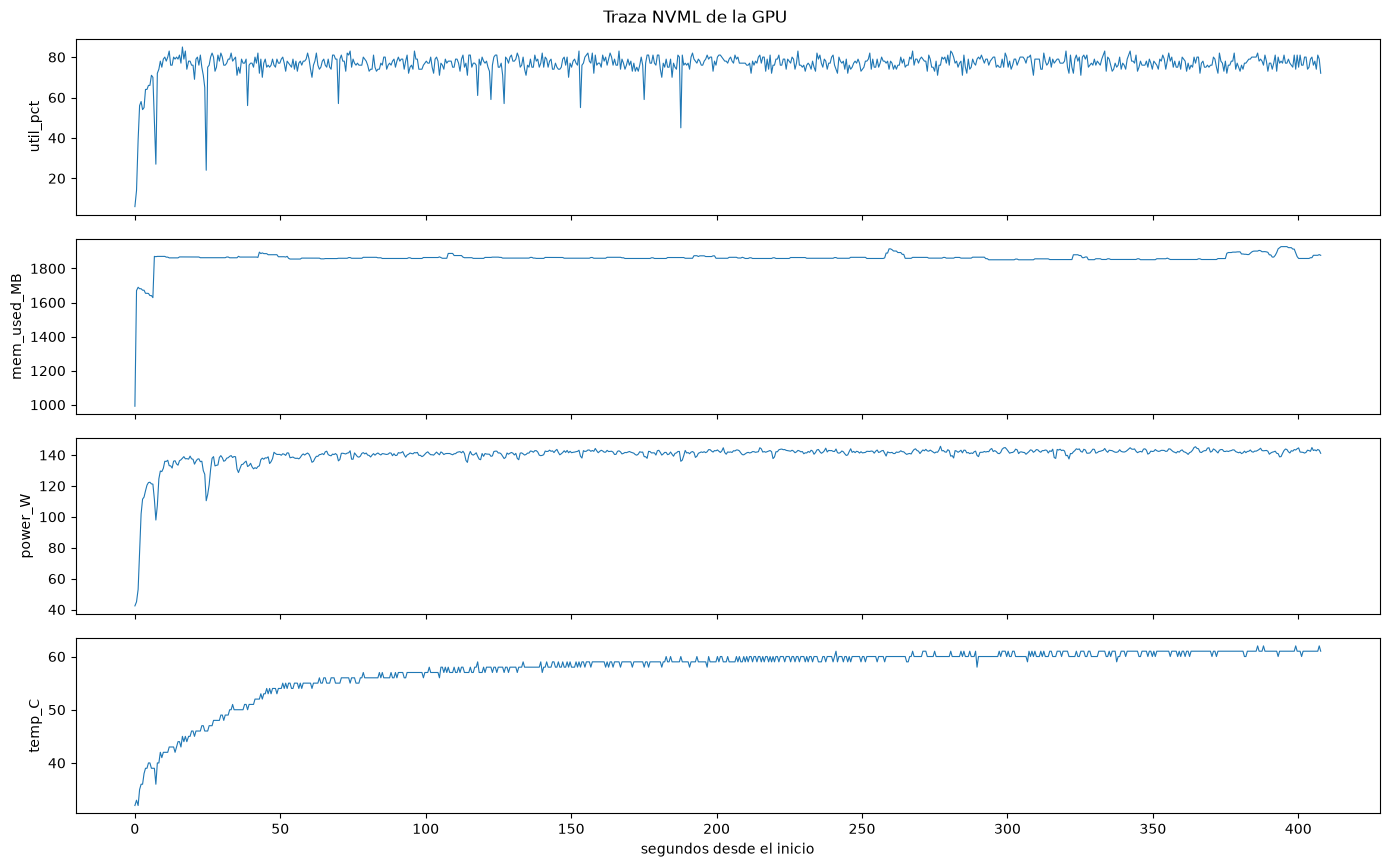

,util_pct,mem_used_MB,power_W,temp_C
count,806.0,806.0,806.0,806.0
mean,76.5,1860.1,140.1,57.5
std,5.9,41.3,7.6,4.9
min,6.0,991.4,42.4,32.0
25%,75.0,1858.6,140.3,57.0
50%,77.0,1860.6,141.7,59.0
75%,79.0,1865.4,142.5,60.0
max,85.0,1928.2,145.7,62.0


In [27]:
# Traza de la GPU durante todo el entrenamiento (si NVML está disponible)
if gpu_trace.empty:
    print("Sin traza NVML (pip install nvidia-ml-py y vuelve a ejecutar el entrenamiento)")
else:
    cols = [c for c in ["util_pct", "mem_used_MB", "power_W", "temp_C"] if gpu_trace[c].notna().any()]
    fig, axes = plt.subplots(len(cols), 1, figsize=(14, 2.2 * len(cols)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, cols):
        ax.plot(gpu_trace["t"], gpu_trace[c], lw=0.8)
        ax.set_ylabel(c)
    axes[-1].set_xlabel("segundos desde el inicio")
    fig.suptitle("Traza NVML de la GPU")
    fig.tight_layout()
    plt.show()
    display(gpu_trace[cols].describe().round(1))

## 7. Evaluación en validación (mejor checkpoint)

Métricas del artículo: accuracy, precision, recall y F1 macro, matriz de confusión y **Acc Gap** = acc train − acc val. La acc de train se mide **sin aumentación**, porque la de las curvas lleva aumentación y dropout y sale más baja de lo que es en realidad.

Recuerda que se evalúa sobre **val**, que también se ha usado para el early stopping y el scheduler. Es una estimación algo optimista; la cifra definitiva saldrá del test al final.

In [28]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, preds = [], []
    for x, y in loader:
        logits = model(x.to(device, non_blocking=True))
        ys.append(y)
        preds.append(logits.argmax(1).cpu())
    return torch.cat(ys).numpy(), torch.cat(preds).numpy()

ckpt = torch.load(ckpt_path, map_location=device, weights_only=True)
model.load_state_dict(ckpt["model"])
print(f"Checkpoint de la época {ckpt['epoch']} (val loss {ckpt['val_loss']:.4f})")

y_val, p_val = predict(model, val_loader)
y_tr, p_tr = predict(model, train_eval_loader)

prec, rec, f1, _ = precision_recall_fscore_support(y_val, p_val, average="macro", zero_division=0)
metrics = {
    "val_acc": (y_val == p_val).mean(),
    "val_precision_macro": prec,
    "val_recall_macro": rec,
    "val_f1_macro": f1,
    "train_acc_noaug": (y_tr == p_tr).mean(),
}
metrics["acc_gap"] = metrics["train_acc_noaug"] - metrics["val_acc"]
display(pd.Series(metrics).round(4).to_frame("MarsCNN"))
print(classification_report(y_val, p_val, target_names=CLASSES, digits=3, zero_division=0))

Checkpoint de la época 72 (val loss 0.2736)


,MarsCNN
val_acc,0.8955
val_precision_macro,0.8987
val_recall_macro,0.8926
val_f1_macro,0.8947
train_acc_noaug,0.9585
acc_gap,0.0630


              precision    recall  f1-score   support

   artifacts      0.971     0.895     0.932        38
     invalid      0.972     0.972     0.972        36
    regolith      0.878     0.935     0.905        46
       rocks      0.854     0.911     0.882        45
rover_tracks      0.818     0.750     0.783        36

    accuracy                          0.896       201
   macro avg      0.899     0.893     0.895       201
weighted avg      0.896     0.896     0.895       201



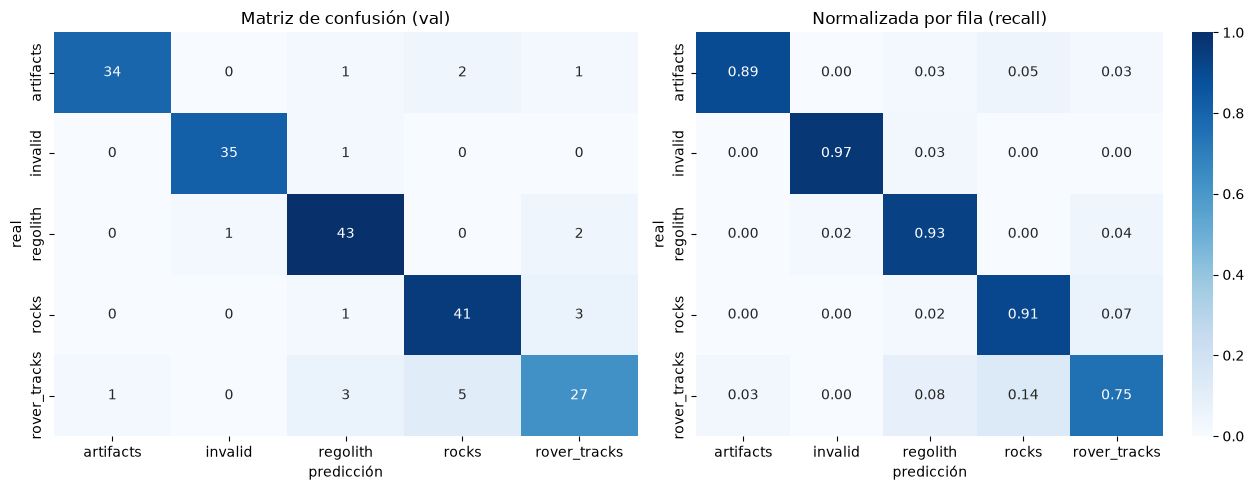

In [29]:
cm = confusion_matrix(y_val, p_val)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0], cbar=False)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
for ax, title in zip(axes, ["Matriz de confusión (val)", "Normalizada por fila (recall)"]):
    ax.set_xlabel("predicción"); ax.set_ylabel("real"); ax.set_title(title)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "confusion_val.png", dpi=150)
plt.show()

### 7.1 Errores de validación
Mirar los fallos suele enseñar más que las métricas: ¿son errores razonables, como regolith confundido con rocks, o etiquetas dudosas?

21 errores de 201


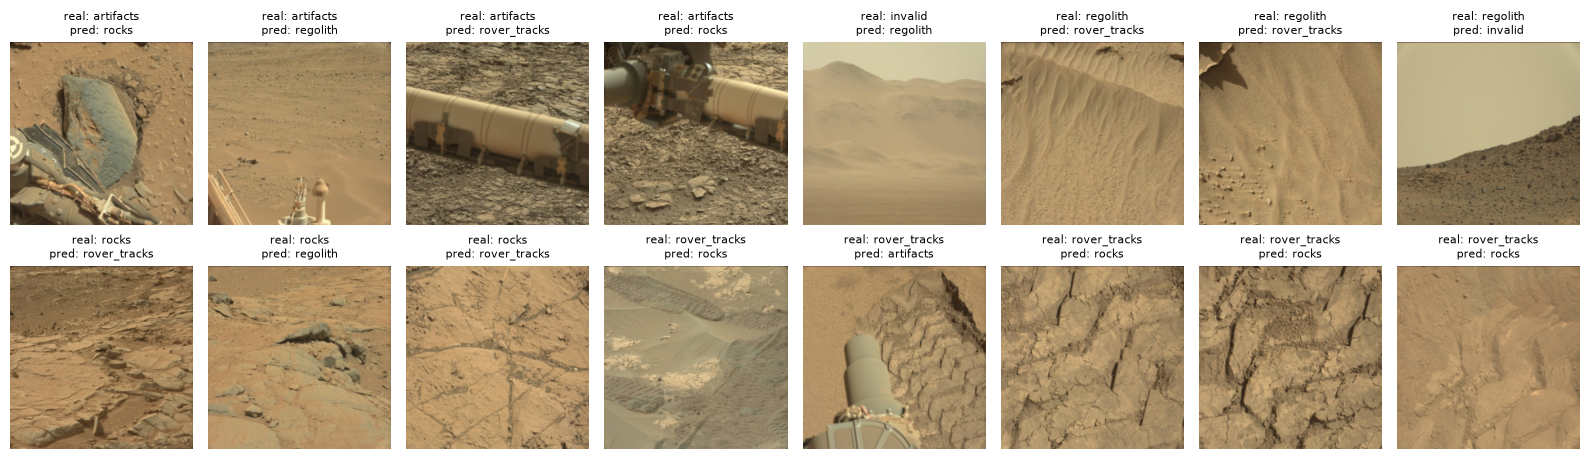

In [30]:
wrong = np.flatnonzero(y_val != p_val)
print(f"{len(wrong)} errores de {len(y_val)}")
show = wrong[:16]
if len(show):
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.8), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, show):
        ax.imshow(val_ds.images[i].permute(1, 2, 0).numpy())
        ax.set_title(f"real: {CLASSES[y_val[i]]}\npred: {CLASSES[p_val[i]]}", fontsize=8)
    fig.tight_layout()
    plt.show()

## 8. Coste de inferencia y de entrenamiento según el batch size

1. **Latencia de inferencia**: ms por imagen con batch 1, medida con eventos CUDA. El artículo la compara entre activaciones; en el rover se clasifica de imagen en imagen.
2. **Benchmark de un paso de entrenamiento** con datos sintéticos ya en la GPU, para aislar el cómputo de la carga de datos. Se mide cómo escalan el throughput y la memoria con el batch size y con AMP, para **MarsCNN y ResNet50**. La fila de ResNet50 anticipa el coste del notebook 02.

El batch 8 del artículo infrautiliza la GPU. Aun así se mantiene para la réplica, porque cambia la dinámica del entrenamiento (BatchNorm y ruido del gradiente).

In [31]:
@torch.no_grad()
def measure_latency(model, batch_size=1, reps=200, warmup=20):
    model.eval()
    x = torch.randn(batch_size, 3, cfg.img_size, cfg.img_size, device=device)
    for _ in range(warmup):
        model(x)
    start, end = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
    times = []
    for _ in range(reps):
        start.record()
        model(x)
        end.record()
        torch.cuda.synchronize()
        times.append(start.elapsed_time(end))
    t = np.array(times)
    return {"latency_ms_mean": t.mean(), "latency_ms_p95": np.percentile(t, 95)}

latency = measure_latency(model)
pd.Series(latency).round(3).to_frame("MarsCNN · batch 1")

,MarsCNN · batch 1
latency_ms_mean,1.387
latency_ms_p95,2.088


In [32]:
def benchmark_train_step(make, batch_sizes, use_amp=False, steps=20, warmup=5, name=""):
    rows = []
    for bs in batch_sizes:
        m = opt = x = y = None
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        row = {"modelo": name, "batch_size": bs, "amp": use_amp}
        try:
            m = make().to(device).train()
            opt = torch.optim.Adam(m.parameters(), lr=1e-3)
            scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
            x = torch.randn(bs, 3, cfg.img_size, cfg.img_size, device=device)
            y = torch.randint(0, len(CLASSES), (bs,), device=device)

            def step():
                opt.zero_grad(set_to_none=True)
                with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                    loss = F.cross_entropy(m(x), y)
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()

            for _ in range(warmup):
                step()
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            for _ in range(steps):
                step()
            torch.cuda.synchronize()
            dt = time.perf_counter() - t0
            row.update(img_per_s=bs * steps / dt, ms_per_step=1000 * dt / steps,
                       peak_mem_MB=torch.cuda.max_memory_allocated() / 1024**2)
        except torch.OutOfMemoryError:
            row.update(img_per_s=np.nan, ms_per_step=np.nan, peak_mem_MB=np.nan, oom=True)
        finally:
            del m, opt, x, y
            torch.cuda.empty_cache()
        rows.append(row)
    return pd.DataFrame(rows)

resnet50 = lambda: torchvision.models.resnet50(num_classes=len(CLASSES))
bench = pd.concat([
    benchmark_train_step(make_model, [8, 16, 32, 64, 128], use_amp=False, name="MarsCNN"),
    benchmark_train_step(make_model, [8, 16, 32, 64, 128], use_amp=True, name="MarsCNN"),
    benchmark_train_step(resnet50, [8, 16, 32, 64], use_amp=False, name="ResNet50"),
    benchmark_train_step(resnet50, [8, 16, 32, 64], use_amp=True, name="ResNet50"),
], ignore_index=True)
bench.to_csv(RESULTS_DIR / "benchmark_batch.csv", index=False)
bench.round(1)

,modelo,batch_size,amp,img_per_s,ms_per_step,peak_mem_MB
0,MarsCNN,8,False,230.0,34.8,711.1
1,MarsCNN,16,False,247.0,64.8,1095.4
2,MarsCNN,32,False,252.6,126.7,1925.6
3,MarsCNN,64,False,262.3,244.0,3801.0
4,MarsCNN,128,False,270.3,473.6,7493.3
5,MarsCNN,8,True,404.3,19.8,318.5
6,MarsCNN,16,True,432.1,37.0,570.4
7,MarsCNN,32,True,460.2,69.5,1074.2
8,MarsCNN,64,True,462.8,138.3,2082.0
9,MarsCNN,128,True,472.7,270.8,4105.5


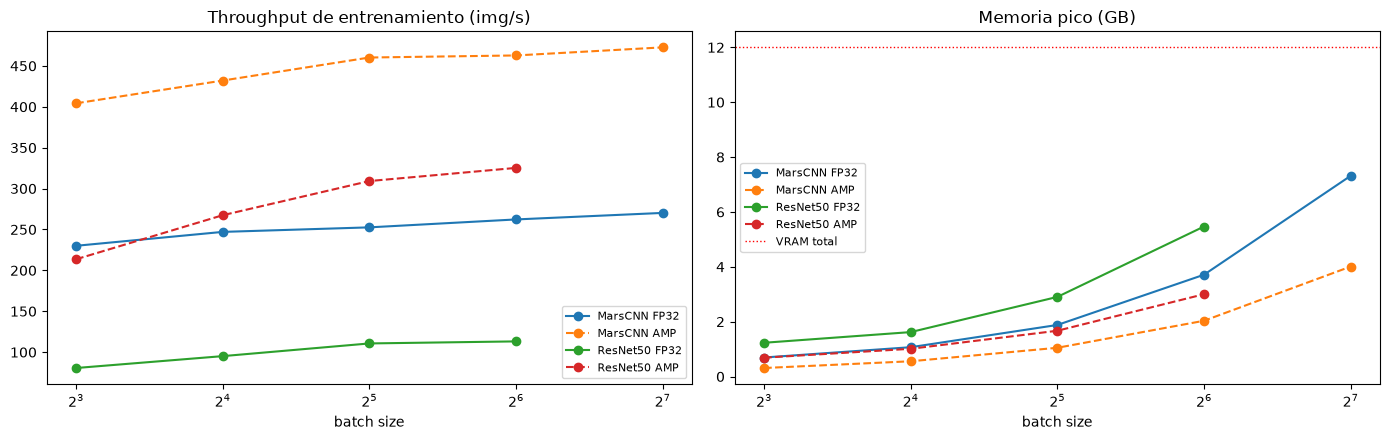

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for (name, amp), g in bench.groupby(["modelo", "amp"]):
    style = "-" if not amp else "--"
    label = f"{name} {'AMP' if amp else 'FP32'}"
    axes[0].plot(g.batch_size, g.img_per_s, style, marker="o", label=label)
    axes[1].plot(g.batch_size, g.peak_mem_MB / 1024, style, marker="o", label=label)
axes[0].set_title("Throughput de entrenamiento (img/s)")
axes[1].set_title("Memoria pico (GB)")
axes[1].axhline(props.total_memory / 1024**3, c="red", lw=1, ls=":", label="VRAM total")
for ax in axes:
    ax.set_xscale("log", base=2); ax.set_xlabel("batch size"); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "benchmark_batch.png", dpi=150)
plt.show()

## 9. Guardar el resumen del experimento
Un JSON por experimento permite después comparar todos los modelos en una sola tabla.

In [35]:
def to_builtin(d):
    return {k: (v.item() if hasattr(v, "item") else v) for k, v in d.items()}

summary = {
    "run": RUN_NAME,
    "model": "MarsCNN",
    "params_M": float(model_stats.loc["MarsCNN", "parámetros (M)"]),
    "gflops": float(model_stats.loc["MarsCNN", "GFLOPs / imagen"]),
    **to_builtin(fit_summary),
    **to_builtin(metrics),
    **to_builtin(latency),
    "mean_epoch_s": float(history["epoch_s"].mean()),
    "mean_train_img_per_s": float(history["train_img_per_s"].mean()),
    "peak_train_mem_MB": float(history["train_peak_mem_MB"].max()),
    "split": SPLIT_CSV.name,
    "cfg": asdict(cfg),
    "env": env_info,
}
with open(RESULTS_DIR / "summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False, default=str)
print("Guardado en", RESULTS_DIR)
pd.Series({k: v for k, v in summary.items() if not isinstance(v, dict)}).to_frame("valor")

Guardado en /mnt/c/Users/Jorge/MarsProject/results/cnn_baseline_v1


,valor
run,cnn_baseline_v1
model,MarsCNN
params_M,2.36
gflops,5.64
best_epoch,72
best_val_loss,0.273637
epochs_run,92
train_time_s,407.905868
val_acc,0.895522
val_precision_macro,0.89871


## 10. Conclusiones

Rellena después de ejecutar:

- **Rendimiento:** val acc y F1 macro. Compáralos con el baseline del artículo (ResNet50 desde cero: 78.11 % acc). Ojo: la partición es distinta y más exigente, porque no comparte soles.
- **Sobreajuste:** el Acc Gap y la distancia entre las curvas de train y val.
- **Clases confundidas:** ¿coinciden con lo que viste en el EDA (`regolith` / `rocks` / `rover_tracks`)?
- **Proceso:** s/época, img/s, si la GPU estaba saturada (utilización) o esperando datos, y la memoria usada.
- **Benchmark:** ¿cuánto se gana con un batch mayor o con AMP? ¿Cabe ResNet50 con batch 8 de sobra?

**Siguiente paso (02):** ResNet50 desde cero con exactamente esta tubería. Cuando vayas a reutilizar `CachedImageDataset`, las transformaciones, `run_epoch`, `fit`, `GPUMonitor` y `benchmark_train_step`, conviene moverlos a un módulo (por ejemplo `src/mars/`) en vez de copiarlos de un notebook a otro.